# Results

Collects the runs of `uv run baseline` (B1, B2, M1, M2) and `uv run train` (M3) from `logs/`: every run
folder holds its config (`.hydra/`), `metrics.json` and `predictions_*.csv`. **Choose the runs to report
in the next cell**; the overview below it lists everything under `LOGS` with its settings.

Where several selected runs share a method and mode (e.g. a sweep), the tables and maps use the run that
is best on `SELECT_SPLIT` by `SELECT_BY`, and report its test results.

In [1]:
from pathlib import Path

LOGS = Path("../logs/train/baseline")  # copy from the cluster without checkpoints, see the README
# Runs to include: glob patterns relative to LOGS, matching run folders or folders above them, e.g.
#   "baseline/b2/multiruns/2026-10-27_09-12-44"      all runs of one sweep
#   "baseline/b2/multiruns/2026-10-27_09-12-44/3"    one run of it
#   "train/m3/runs/*"                                 all M3 runs
#   "*"                                               everything
RUNS = [
    "*",
]
EXCLUDE = []  # patterns of runs to leave out again

SELECT_SPLIT = "valid"   # runs are chosen on this split ...
SELECT_BY = "median_km"  # ... by this metric (*_km and loss: lower is better, the rest: higher)
LEVEL = "speaker"        # "speaker" (unit scores averaged per speaker) or "unit" (clip / segment)

In [2]:
import fnmatch
import json
import os

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from omegaconf import OmegaConf

from maloney.geo import Grid

ROOT = Path.cwd().resolve().parent
os.environ.setdefault("PROJECT_ROOT", str(ROOT))  # what rootutils sets when the runs start
OmegaConf.register_new_resolver("hydra", lambda *_: "", replace=True)  # ${hydra:...} only names folders
LOWER_IS_BETTER = {"mean_km", "median_km", "loss"}
SETTINGS = ["encoder", "layer", "unit", "segment_s", "data_split", "cell_km", "sigma_km", "neighbour_km", "lr", "epochs"]
METRICS = ["region_acc", "region_acc_majority", "region_f1", "cell_acc", "acc@0", "acc@1", "acc@2", "acc@3",
           "median_km", "mean_km"]
pd.set_option("display.max_columns", 50, "display.width", 250)
plt.rcParams["axes.prop_cycle"] = plt.cycler(color=plt.get_cmap("tab20").colors)  # many methods x modes


def name(row) -> str:
    return row["method"] if row["mode"] == "-" else f"{row['method']} {row['mode']}"


def run_settings(run: Path) -> dict:
    """What distinguishes a run, from its resolved config."""
    cfg = OmegaConf.create(OmegaConf.to_container(OmegaConf.load(run / ".hydra/config.yaml"), resolve=True))
    choices = OmegaConf.load(run / ".hydra/hydra.yaml").hydra.runtime.choices
    get = lambda key: OmegaConf.select(cfg, key)  # noqa: E731
    baseline = cfg.task_name == "baseline"
    unit = get("unit") if baseline else ("segment" if get("data.segment_duration") else "clip")
    km = lambda v: None if v is None else v / 1000  # noqa: E731
    return {
        "run": run.relative_to(LOGS).as_posix(),
        "task": cfg.task_name,
        "method": choices.get("method") if baseline else "m3",
        "mode": get("geo.mapping.mode"),
        "encoder": (Path(get("embeddings.path")).stem if baseline else get("model.name")).split("__")[-1].split("/")[-1],
        "layer": get("embeddings.layer") if baseline else (get("model.pool_layer") or "last"),
        "unit": unit,
        "segment_s": get("data.segment_duration") if unit == "segment" else None,
        "data_split": Path(get("data.split_dir")).name if get("data.split_dir") else "official",
        "cell_km": km(get("geo.grid.cell_size")),
        "sigma_km": km(get("geo.mapping.sigma")),
        "neighbour_km": km(get("geo.mapping.neighbour_distance")),
        "lr": None if baseline else get("optim.lr"),
        "epochs": None if baseline else get("trainer.epochs"),
        "_cfg": cfg,
    }


def metric_rows(run: Path, settings: dict) -> list[dict]:
    """One row per method variant x split x level of a run's metrics.json."""
    rows = []
    for key, values in json.loads((run / "metrics.json").read_text()).items():
        if settings["task"] == "train":  # prototype_<mode>/<split>/<level> or head/<split>/<level>
            variant, split, level = key.split("/")
            method = "m3-head" if variant == "head" else "m3"
            mode = settings["mode"] if variant == "head" else variant.removeprefix("prototype_")
            file = f"predictions_{split}_{level}_{variant.removeprefix('prototype_')}.csv"
        else:
            split, level = key.split("/")
            method, mode = settings["method"], "-" if settings["method"] == "b1" else settings["mode"]
            file = f"predictions_{split}_{level}.csv"
        rows.append({**settings, "method": method, "mode": mode, "split": split, "level": level,
                     **values, "predictions": run / file})
    return rows


def matches(run: str, patterns: list[str]) -> bool:
    return any(fnmatch.fnmatch(run, p) or fnmatch.fnmatch(run, p.rstrip("/") + "/*") for p in patterns)


all_runs = sorted({f.parent for f in LOGS.rglob("metrics.json")})
runs = [r for r in all_runs if matches(r.relative_to(LOGS).as_posix(), RUNS)
        and not matches(r.relative_to(LOGS).as_posix(), EXCLUDE)]
settings = {r: run_settings(r) for r in all_runs}
results = pd.DataFrame([row for r in runs for row in metric_rows(r, settings[r])])

overview = pd.DataFrame([{k: v for k, v in s.items() if k != "_cfg"} for s in settings.values()])
overview.insert(0, "selected", [r in runs for r in all_runs])
print(f"{len(runs)} of {len(all_runs)} runs under {LOGS} selected, {len(results)} result rows")
display(overview)

12 of 12 runs under ../logs/train/baseline selected, 48 result rows


,selected,run,task,method,mode,encoder,layer,unit,segment_s,data_split,cell_km,sigma_km,neighbour_km,lr,epochs
0,True,dev/multiruns/2026-10-26_17-21-00/2026-10-26_1...,baseline,b1,centroid,whisper-large-v3,16,segment,20,speakers_v1,5.0,10.0,2.0,None,None
1,True,dev/multiruns/2026-10-26_17-21-00/2026-10-26_1...,baseline,b1,uniform,whisper-large-v3,16,segment,20,speakers_v1,5.0,10.0,2.0,None,None
2,True,dev/multiruns/2026-10-26_17-21-00/2026-10-26_1...,baseline,m2,uniform,whisper-large-v3,16,segment,20,speakers_v1,5.0,10.0,2.0,None,None
3,True,dev/multiruns/2026-10-26_17-21-00/2026-10-26_1...,baseline,m2,gaussian,whisper-large-v3,16,segment,20,speakers_v1,5.0,10.0,2.0,None,None
4,True,dev/multiruns/2026-10-26_17-21-00/2026-10-26_1...,baseline,b1,gaussian,whisper-large-v3,16,segment,20,speakers_v1,5.0,10.0,2.0,None,None
5,True,dev/multiruns/2026-10-26_17-21-00/2026-10-26_1...,baseline,b2,centroid,whisper-large-v3,16,segment,20,speakers_v1,5.0,10.0,2.0,None,None
6,True,dev/multiruns/2026-10-26_17-21-00/2026-10-26_1...,baseline,b2,uniform,whisper-large-v3,16,segment,20,speakers_v1,5.0,10.0,2.0,None,None
7,True,dev/multiruns/2026-10-26_17-21-00/2026-10-26_1...,baseline,b2,gaussian,whisper-large-v3,16,segment,20,speakers_v1,5.0,10.0,2.0,None,None
8,True,dev/multiruns/2026-10-26_17-21-00/2026-10-26_1...,baseline,m1,centroid,whisper-large-v3,16,segment,20,speakers_v1,5.0,10.0,2.0,None,None
9,True,dev/multiruns/2026-10-26_17-21-00/2026-10-26_1...,baseline,m1,uniform,whisper-large-v3,16,segment,20,speakers_v1,5.0,10.0,2.0,None,None


## Main table

Per method and mapping mode the selected run that is best on `SELECT_SPLIT` (by `SELECT_BY` at `LEVEL`), with
its test results at `LEVEL` and, below, the same runs at the other level. For M1, M2 and the M3 head the mode only changes how a predicted cell maps back to a
dialect region (`region_*`), for B1 nothing; `region_acc` uses the paper's lenient rule, `region_acc_majority`
the region with the most weight in the predicted cell. Columns: only the settings that differ.

In [3]:
def at_level(df: pd.DataFrame, level: str) -> pd.DataFrame:
    return df[df["level"] == "speaker"] if level == "speaker" else df[df["level"] != "speaker"]


def best(df: pd.DataFrame, level: str = LEVEL, by: str = SELECT_BY, split: str = SELECT_SPLIT,
         chosen_at: str = LEVEL) -> pd.DataFrame:
    """The run per (method, mode) that is best on `split` by `by` at level `chosen_at`, and its rows on
    every split at `level`."""
    candidates = at_level(df[df["split"] == split], chosen_at)
    chosen = candidates.sort_values(by, ascending=by in LOWER_IS_BETTER).groupby(["method", "mode"]).head(1)
    keys = chosen[["run", "method", "mode"]].assign(selected_by=chosen[by].to_numpy())
    return at_level(df, level).merge(keys, on=["run", "method", "mode"])


def varying(df: pd.DataFrame) -> list[str]:
    return [c for c in SETTINGS if df[c].astype(str).nunique() > 1]


def report(level: str, split: str = "test") -> pd.DataFrame:
    rows = best(results, level)
    table = rows[rows["split"] == split].sort_values(["method", "mode"])
    columns = ["method", "mode", *varying(results), "n", "selected_by", *METRICS]
    lower = [m for m in METRICS if m in LOWER_IS_BETTER]
    return (table[columns].style.format(precision=3, na_rep="")
            .format({"n": "{:.0f}", **{m: "{:.1f}" for m in lower}})
            .highlight_max(subset=[m for m in METRICS if m not in lower], props="font-weight: bold")
            .highlight_min(subset=lower, props="font-weight: bold").hide(axis="index"))


print(f"test, per {LEVEL} (selected_by: {SELECT_SPLIT} {SELECT_BY} per {LEVEL})")
display(report(LEVEL))
other = "unit" if LEVEL == "speaker" else "speaker"
print(f"\nthe same runs, test, per {other}")
display(report(other))

test, per speaker (selected_by: valid median_km per speaker)


method,mode,n,selected_by,region_acc,region_acc_majority,region_f1,cell_acc,acc@0,acc@1,acc@2,acc@3,median_km,mean_km
b1,-,14,96.052437,0.142857,0.142857,0.142857,0.071429,0.071429,0.071429,0.142857,0.142857,82.3,80.7
b2,centroid,14,80.638364,0.071429,0.071429,0.047619,0.000000,0.000000,0.000000,0.071429,0.071429,79.3,86.6
b2,gaussian,14,89.953943,0.428571,0.214286,0.352381,0.142857,0.000000,0.000000,0.000000,0.000000,75.2,90.8
b2,uniform,14,87.223387,0.285714,0.214286,0.228571,0.071429,0.000000,0.000000,0.071429,0.071429,94.5,90.8
m1,centroid,14,121.628205,0.214286,0.214286,0.128571,0.071429,0.071429,0.071429,0.142857,0.142857,63.6,74.1
m1,gaussian,14,121.628205,0.500000,0.214286,0.490476,0.357143,0.071429,0.071429,0.142857,0.142857,63.6,74.1
m1,uniform,14,121.628205,0.214286,0.214286,0.128571,0.142857,0.071429,0.071429,0.142857,0.142857,63.6,74.1
m2,centroid,14,81.133152,0.214286,0.214286,0.209524,0.000000,0.000000,0.000000,0.000000,0.071429,70.0,77.6
m2,gaussian,14,100.003257,0.500000,0.214286,0.457143,0.285714,0.000000,0.000000,0.000000,0.071429,70.0,77.6
m2,uniform,14,100.003257,0.214286,0.214286,0.209524,0.000000,0.000000,0.000000,0.000000,0.071429,70.0,77.6



the same runs, test, per unit


method,mode,n,selected_by,region_acc,region_acc_majority,region_f1,cell_acc,acc@0,acc@1,acc@2,acc@3,median_km,mean_km
b1,-,1564,96.052437,0.131074,0.131074,0.138402,0.075448,0.075448,0.099744,0.113811,0.117008,82.9,84.2
b2,centroid,1564,80.638364,0.132992,0.132992,0.124541,0.006394,0.006394,0.010870,0.038363,0.060102,85.9,85.2
b2,gaussian,1564,89.953943,0.334399,0.157289,0.330774,0.202685,0.000000,0.001918,0.007033,0.021100,97.8,93.5
b2,uniform,1564,87.223387,0.181586,0.143862,0.169479,0.048593,0.000000,0.001918,0.023018,0.037084,97.6,93.3
m1,centroid,1564,121.628205,0.104859,0.104859,0.095846,0.008312,0.008312,0.008951,0.047954,0.058184,84.6,86.7
m1,gaussian,1564,121.628205,0.407289,0.104859,0.401809,0.228261,0.008312,0.008951,0.047954,0.058184,84.6,86.7
m1,uniform,1564,121.628205,0.122762,0.104859,0.107421,0.047954,0.008312,0.008951,0.047954,0.058184,84.6,86.7
m2,centroid,1564,81.133152,0.196292,0.196292,0.163493,0.020460,0.020460,0.023018,0.034527,0.078645,81.5,80.4
m2,gaussian,1564,100.003257,0.434783,0.195013,0.416801,0.328005,0.019821,0.020460,0.031330,0.075448,81.5,80.2
m2,uniform,1564,100.003257,0.192455,0.192455,0.159481,0.029412,0.018542,0.019182,0.029412,0.075448,81.5,80.5


## All selected results

Every split, level and method variant of the selected runs.

In [4]:
display(results.drop(columns=["_cfg", "predictions"]).sort_values(["method", "mode", "split", "level", "run"])
        .style.format(precision=3, na_rep="").hide(axis="index"))

run,task,method,mode,encoder,layer,unit,segment_s,data_split,cell_km,sigma_km,neighbour_km,lr,epochs,split,level,n,region_acc,region_f1,region_acc_majority,cell_acc,acc@0,acc@1,acc@2,acc@3,mean_km,median_km
dev/multiruns/2026-10-26_17-21-00/2026-10-26_17-21-00/0,baseline,b1,-,whisper-large-v3,16,segment,20,speakers_v1,5.000,10.000,2.000,,,test,segment,1564,0.131,0.138,0.131,0.075,0.075,0.100,0.114,0.117,84.194,82.926
dev/multiruns/2026-10-26_17-21-00/2026-10-26_17-21-00/1,baseline,b1,-,whisper-large-v3,16,segment,20,speakers_v1,5.000,10.000,2.000,,,test,segment,1564,0.131,0.138,0.131,0.114,0.075,0.100,0.114,0.117,84.194,82.926
dev/multiruns/2026-10-26_17-21-00/2026-10-26_17-21-00/2,baseline,b1,-,whisper-large-v3,16,segment,20,speakers_v1,5.000,10.000,2.000,,,test,segment,1564,0.131,0.138,0.131,0.131,0.075,0.100,0.114,0.117,84.194,82.926
dev/multiruns/2026-10-26_17-21-00/2026-10-26_17-21-00/0,baseline,b1,-,whisper-large-v3,16,segment,20,speakers_v1,5.000,10.000,2.000,,,test,speaker,14,0.143,0.143,0.143,0.071,0.071,0.071,0.143,0.143,80.707,82.264
dev/multiruns/2026-10-26_17-21-00/2026-10-26_17-21-00/1,baseline,b1,-,whisper-large-v3,16,segment,20,speakers_v1,5.000,10.000,2.000,,,test,speaker,14,0.143,0.143,0.143,0.143,0.071,0.071,0.143,0.143,80.707,82.264
dev/multiruns/2026-10-26_17-21-00/2026-10-26_17-21-00/2,baseline,b1,-,whisper-large-v3,16,segment,20,speakers_v1,5.000,10.000,2.000,,,test,speaker,14,0.143,0.143,0.143,0.143,0.071,0.071,0.143,0.143,80.707,82.264
dev/multiruns/2026-10-26_17-21-00/2026-10-26_17-21-00/0,baseline,b1,-,whisper-large-v3,16,segment,20,speakers_v1,5.000,10.000,2.000,,,valid,segment,2490,0.107,0.141,0.107,0.000,0.000,0.000,0.010,0.010,96.614,98.162
dev/multiruns/2026-10-26_17-21-00/2026-10-26_17-21-00/1,baseline,b1,-,whisper-large-v3,16,segment,20,speakers_v1,5.000,10.000,2.000,,,valid,segment,2490,0.107,0.141,0.107,0.010,0.000,0.000,0.010,0.010,96.614,98.162
dev/multiruns/2026-10-26_17-21-00/2026-10-26_17-21-00/2,baseline,b1,-,whisper-large-v3,16,segment,20,speakers_v1,5.000,10.000,2.000,,,valid,segment,2490,0.107,0.141,0.107,0.071,0.000,0.000,0.010,0.010,96.614,98.162
dev/multiruns/2026-10-26_17-21-00/2026-10-26_17-21-00/0,baseline,b1,-,whisper-large-v3,16,segment,20,speakers_v1,5.000,10.000,2.000,,,valid,speaker,14,0.214,0.262,0.214,0.000,0.000,0.000,0.000,0.000,88.035,96.052


## Sweeps

`SELECT_SPLIT` `SELECT_BY` (at `LEVEL`) against every setting that differs between the selected runs. A
line connects runs of one method and mode whose other settings are equal.

In [5]:
def plot_sweeps(df: pd.DataFrame, metric: str = SELECT_BY, split: str = SELECT_SPLIT, level: str = LEVEL):
    data = at_level(df[df["split"] == split], level)
    params = [p for p in varying(data) if data[p].notna().sum() > 1]
    if not params:
        print("no setting differs between the selected runs")
        return
    lines = {}  # param -> [(label, x, y)]: runs of one method and mode that differ only in param
    for param in params:
        others = [p for p in varying(data) if p != param]
        for key, g in data.dropna(subset=[param]).groupby(["method", "mode", *others], dropna=False):
            if g[param].nunique() > 1:
                g = g.sort_values(param)
                x = g[param] if pd.api.types.is_numeric_dtype(g[param]) else g[param].astype(str)
                label = name(dict(method=key[0], mode=key[1])) + "".join(
                    f", {p}={v}" for p, v in zip(others, key[2:]) if pd.notna(v))
                lines.setdefault(param, []).append((label, x, g[metric]))
    if not lines:
        print("no two selected runs of a method and mode differ in only one setting")
        return
    fig, axes = plt.subplots(1, len(lines), figsize=(5 * len(lines), 4), squeeze=False)
    for ax, (param, param_lines) in zip(axes[0], lines.items()):
        for label, x, y in param_lines:
            ax.plot(x, y, marker="o", label=label)
        ax.set_xlabel(param)
        ax.set_ylabel(f"{split} {metric} ({level})")
        ax.grid(alpha=0.3)
        ax.legend(fontsize=7)
    plt.tight_layout()
    plt.show()


plot_sweeps(results)

no setting differs between the selected runs


## Maps

For the best run per method and mode (as in the main table), on the test split at `LEVEL`. First: true
municipalities (blue) and predicted cells (red, sized by how many units were put there), connected by a line
per unit (like the paper's Figure 4). Second: median error per municipality.

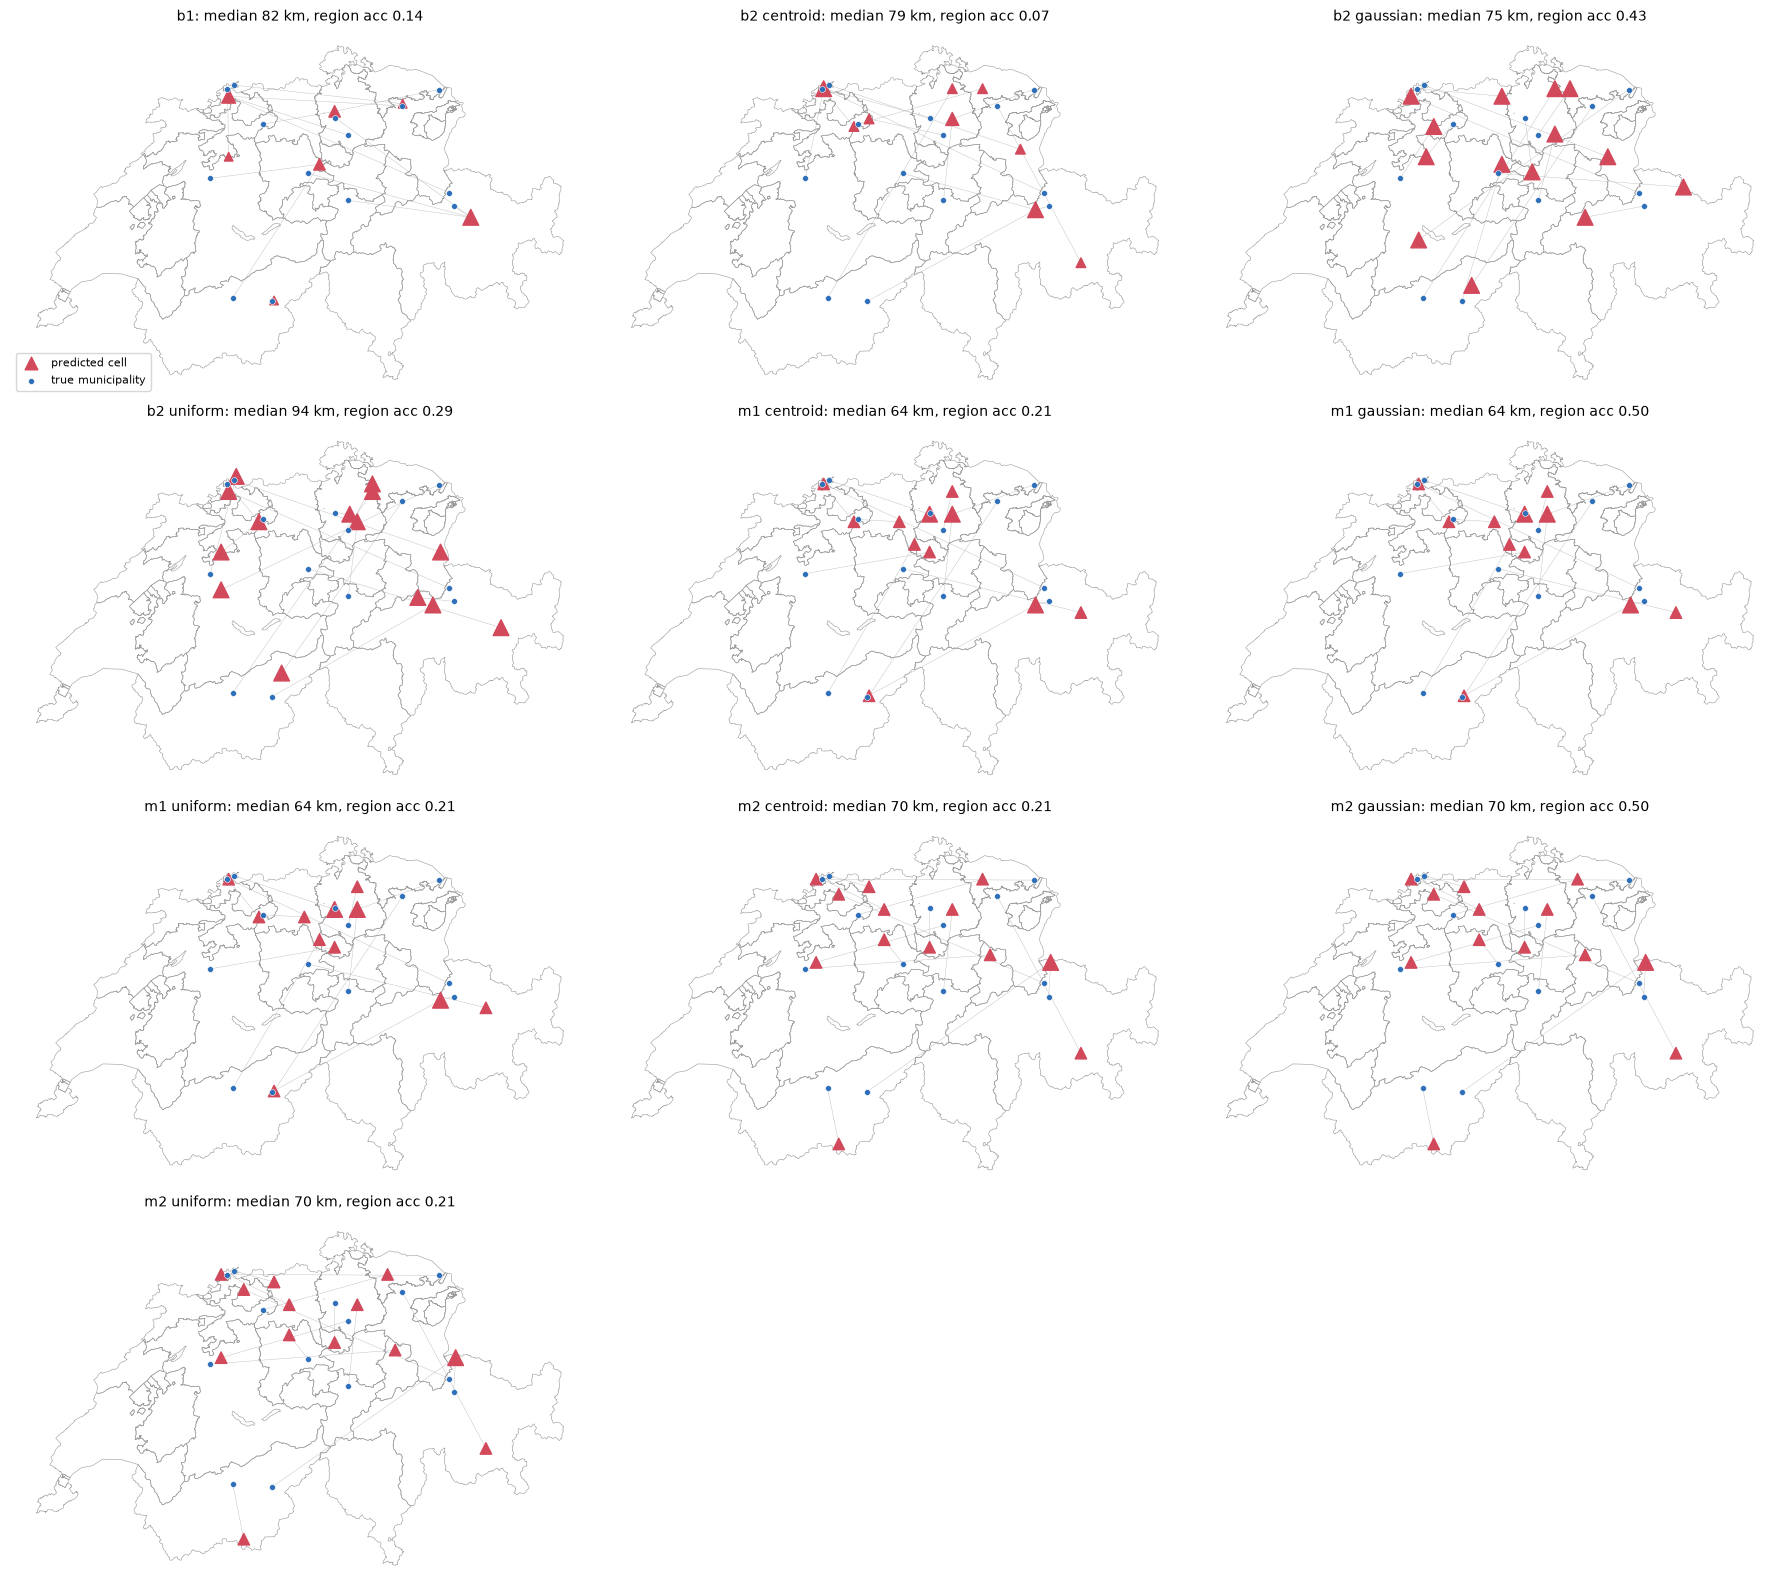

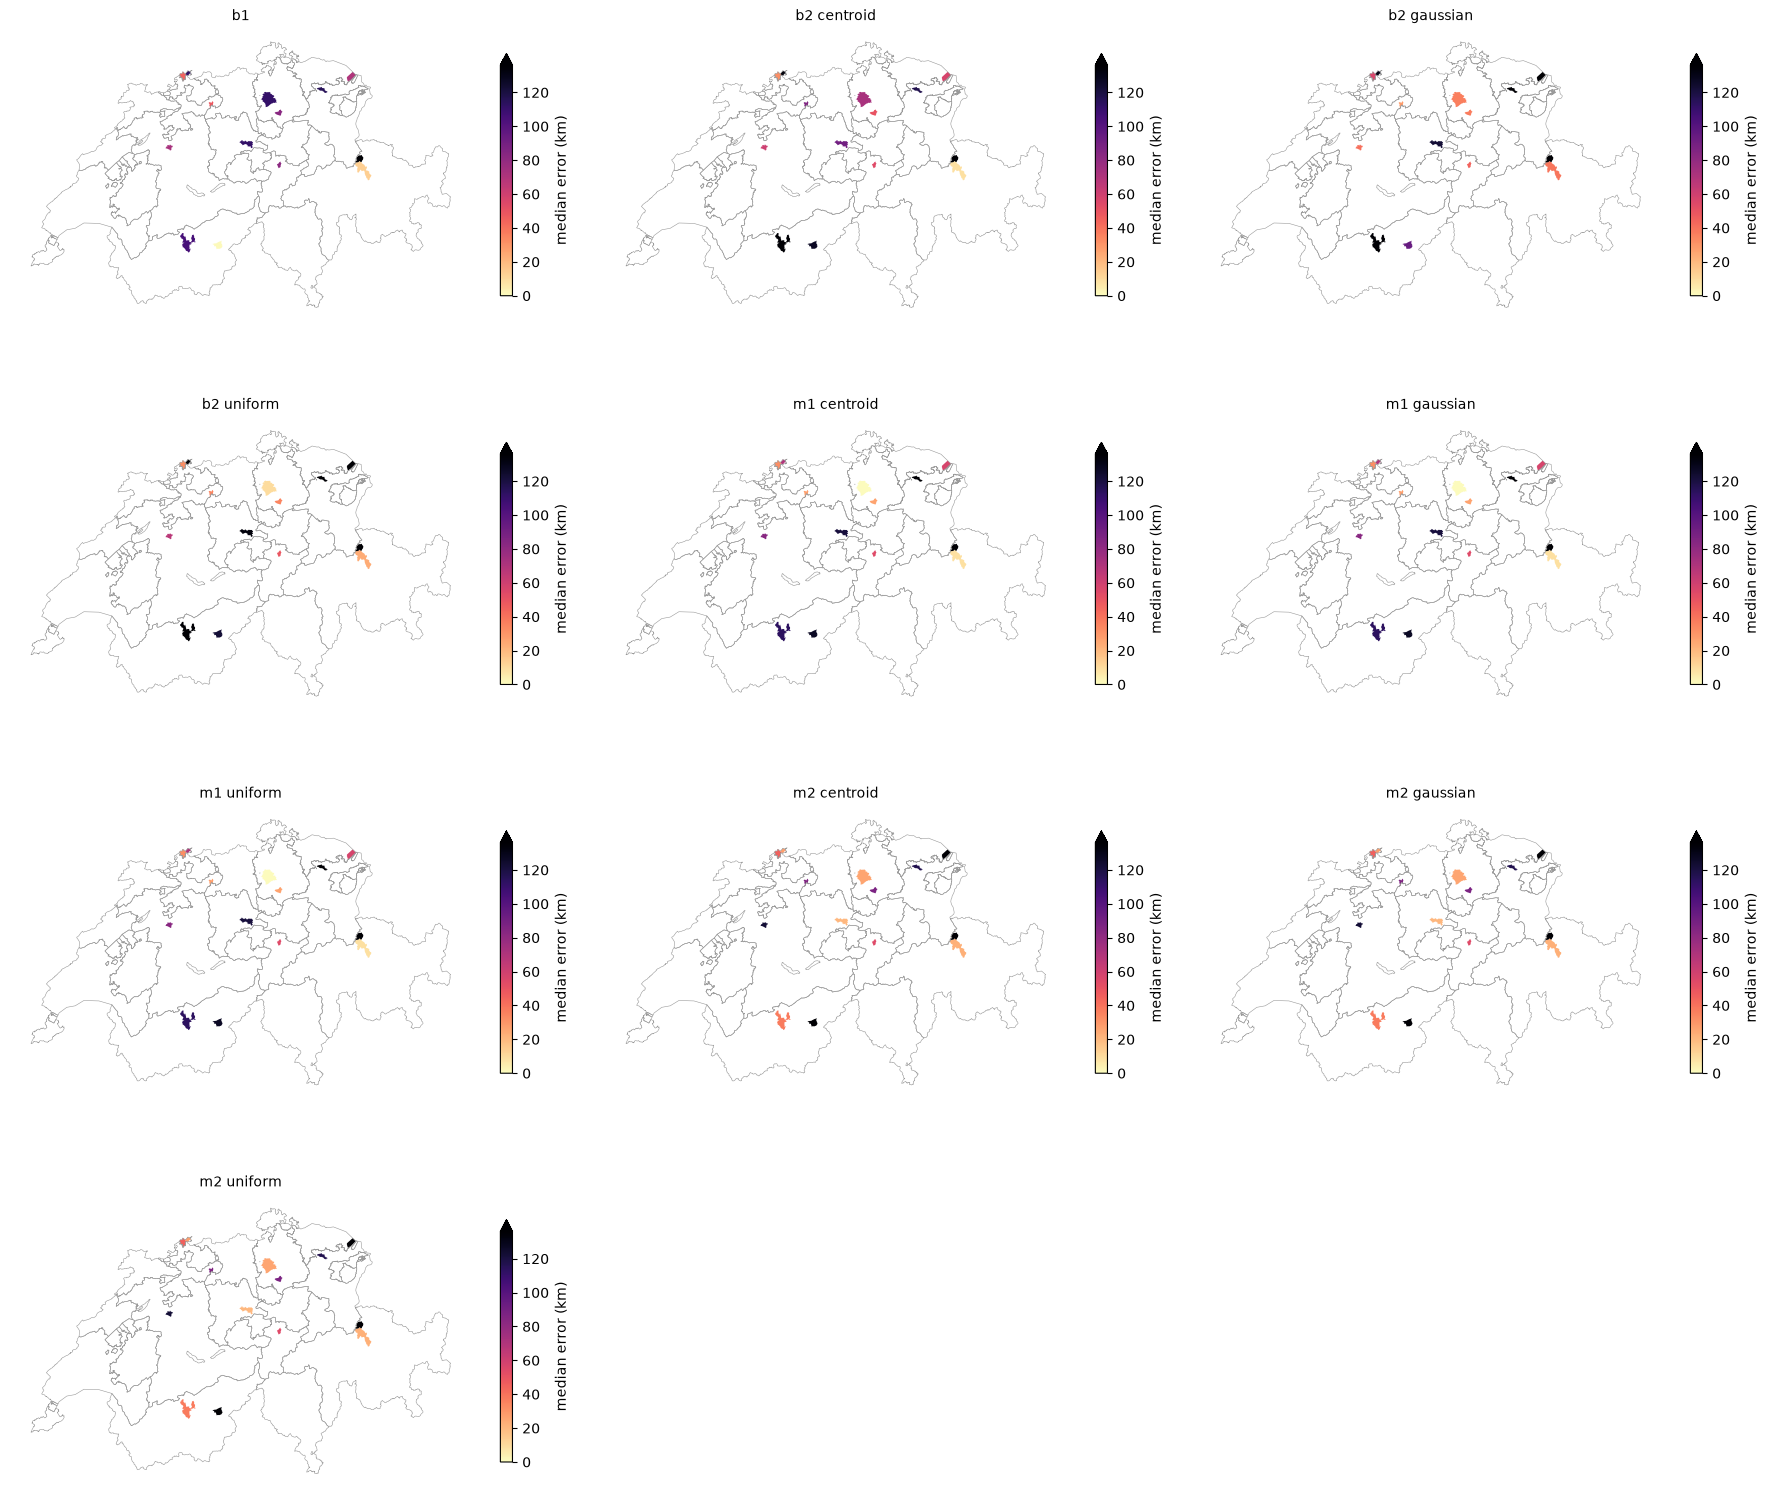

In [6]:
GEO = ROOT / "data" / "geo"
cantons = gpd.read_file(GEO / "cantons.geojson")
municipalities = gpd.read_file(GEO / "municipalities.geojson")


def predictions(row: pd.Series) -> pd.DataFrame:
    p = pd.read_csv(row["predictions"])
    if "pred_E" not in p:  # runs from before the predicted coordinates were stored
        grid = Grid.from_file(GEO / "cantons.geojson", row["cell_km"] * 1000)
        p["pred_E"], p["pred_N"] = grid.midpoints[p["pred_cell"], 0], grid.midpoints[p["pred_cell"], 1]
    return p


def panels(n: int, width: float = 6, height: float = 4):
    cols = min(n, 3)
    fig, axes = plt.subplots((n + cols - 1) // cols, cols, figsize=(width * cols, height * ((n + cols - 1) // cols)),
                             squeeze=False)
    for ax in axes.flat[n:]:
        ax.set_visible(False)
    return fig, axes.flat


chosen = best(results)
chosen = chosen[chosen["split"] == "test"].sort_values(["method", "mode"]).reset_index(drop=True)

fig, axes = panels(len(chosen))
for ax, (_, row) in zip(axes, chosen.iterrows()):
    p = predictions(row)
    cantons.boundary.plot(ax=ax, color="#999999", linewidth=0.4)
    for t, q in zip(p[["muni_E", "muni_N"]].to_numpy(), p[["pred_E", "pred_N"]].to_numpy()):
        ax.plot([t[0], q[0]], [t[1], q[1]], color="#bbbbbb", linewidth=0.3, zorder=1)
    counts = p.groupby(["pred_E", "pred_N"]).size().reset_index(name="n")
    ax.scatter(counts["pred_E"], counts["pred_N"], s=8 + 120 * counts["n"] / counts["n"].max(), marker="^",
               color="#d1495b", label="predicted cell", zorder=3)
    true = p.drop_duplicates("bfs_nr")
    ax.scatter(true["muni_E"], true["muni_N"], s=18, color="#2e6fba", edgecolor="white", linewidth=0.4,
               label="true municipality", zorder=4)
    ax.set_title(f"{name(row)}: median {row['median_km']:.0f} km, region acc {row['region_acc']:.2f}",
                 fontsize=10)
    ax.set_axis_off()
    ax.set_aspect("equal")
axes[0].legend(loc="lower left", fontsize=8)
plt.tight_layout()
plt.show()

fig, axes = panels(len(chosen))
for ax, (_, row) in zip(axes, chosen.iterrows()):
    error = predictions(row).groupby("bfs_nr")["error_km"].median().rename("median_error_km").reset_index()
    shapes = municipalities.merge(error, on="bfs_nr")
    cantons.boundary.plot(ax=ax, color="#999999", linewidth=0.4)
    shapes.plot(ax=ax, column="median_error_km", cmap="magma_r", vmin=0, vmax=chosen["mean_km"].max() * 1.5,
                legend=True, legend_kwds={"shrink": 0.6, "label": "median error (km)"})
    ax.set_title(name(row), fontsize=10)
    ax.set_axis_off()
    ax.set_aspect("equal")
plt.tight_layout()
plt.show()

## Dialect regions

Confusion between the true and the predicted dialect region (rows: true, normalised per row) for the same runs,
with the paper's lenient rule (`pred_region`) and the strict majority region. B1 predicts regions directly.

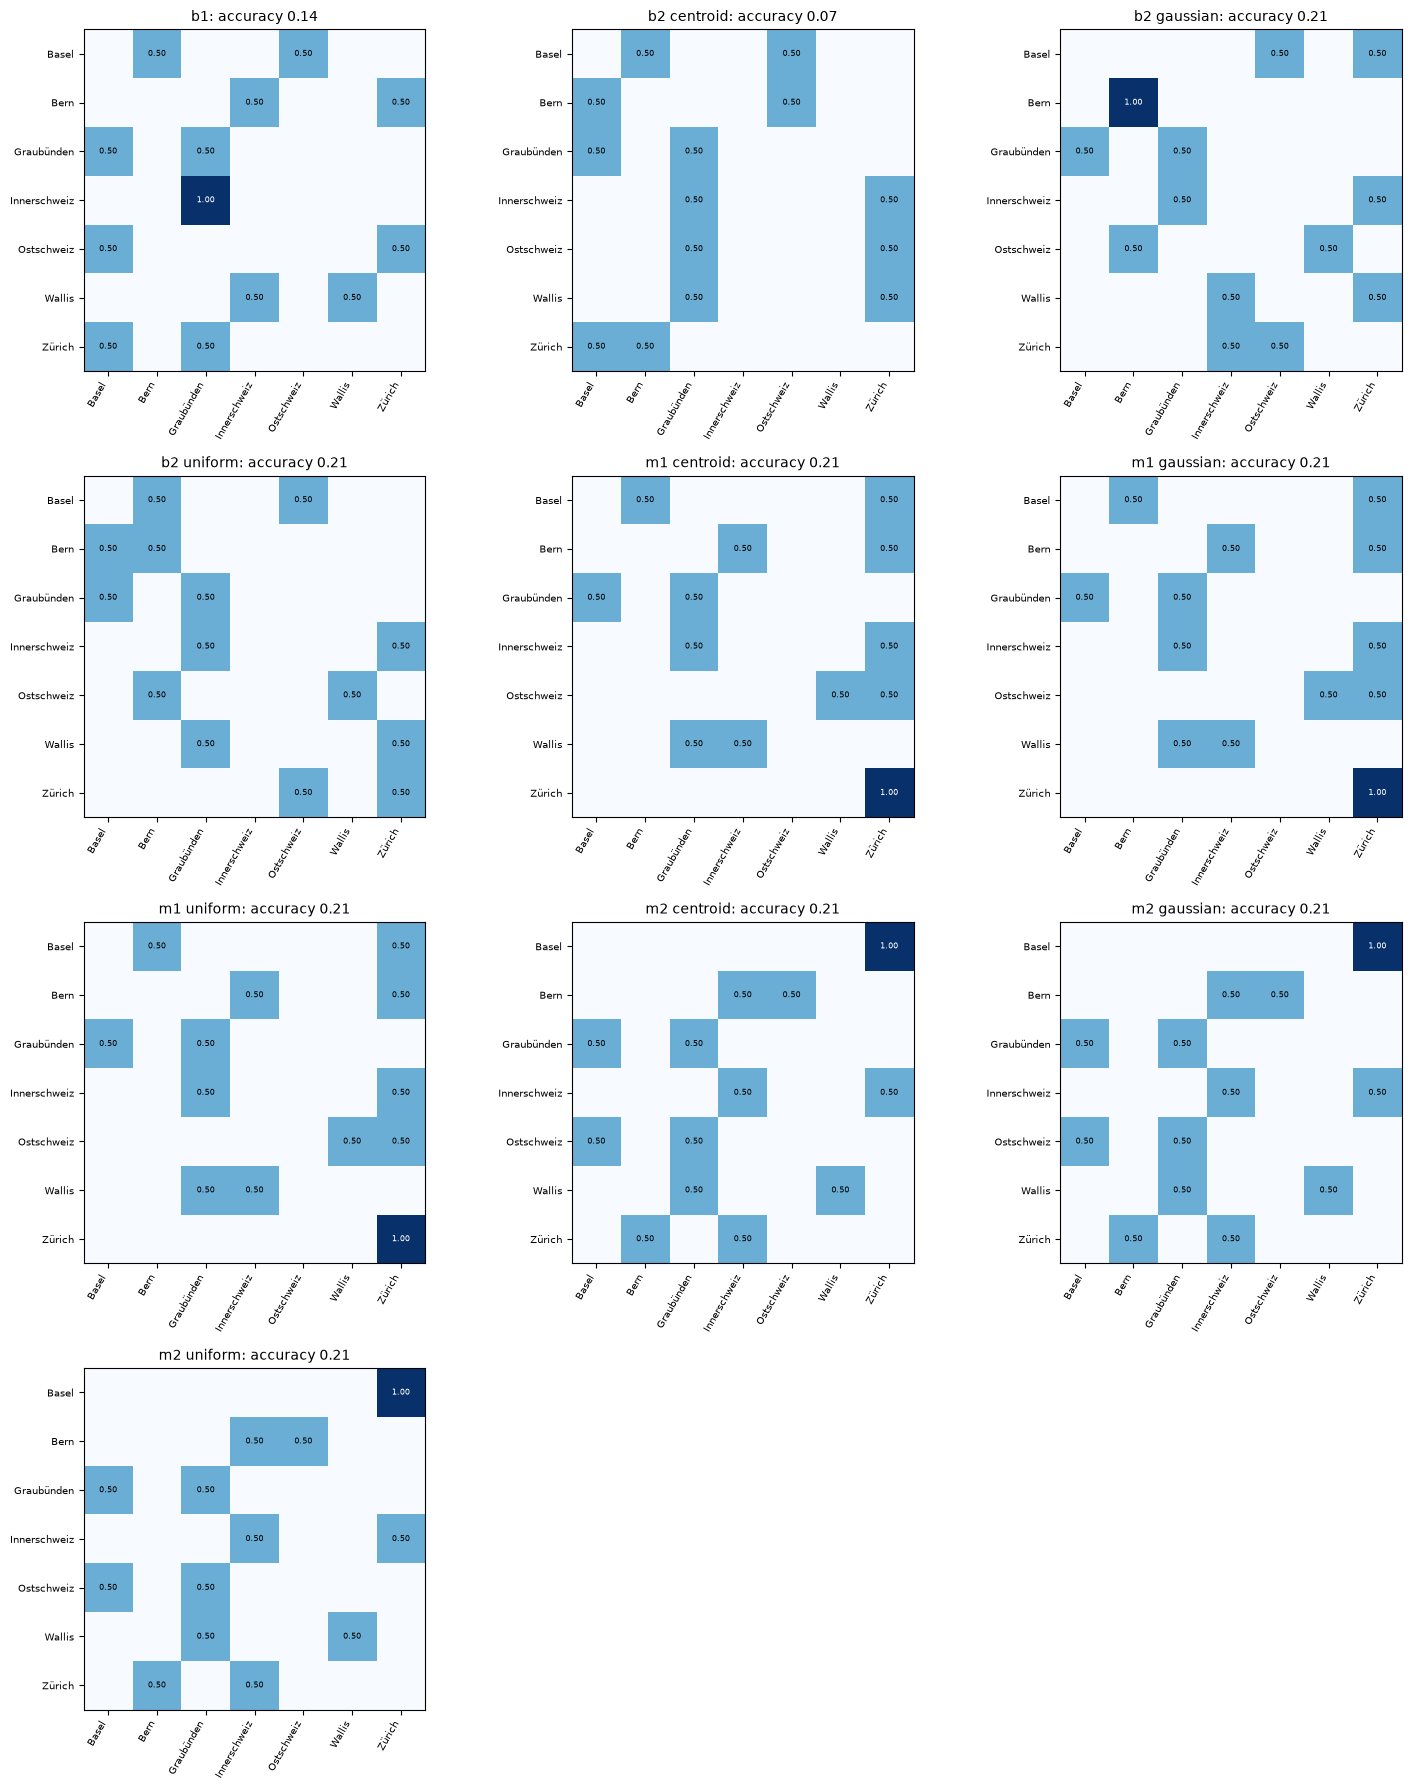

In [7]:
RULE = "pred_region_majority"  # or "pred_region" (the paper's lenient rule)

regions = sorted(pd.concat([predictions(row)["dialect_region"] for _, row in chosen.iterrows()]).unique())
fig, axes = panels(len(chosen), width=5, height=4.5)
for ax, (_, row) in zip(axes, chosen.iterrows()):
    p = predictions(row)
    matrix = pd.crosstab(p["dialect_region"], p[RULE]).reindex(index=regions, columns=regions + ["<none>"], fill_value=0)
    matrix = matrix.loc[:, (matrix.sum() > 0) | matrix.columns.isin(regions)]
    shares = matrix.div(matrix.sum(axis=1).replace(0, 1), axis=0)
    ax.imshow(shares, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(shares.columns)), shares.columns, rotation=60, ha="right", fontsize=7)
    ax.set_yticks(range(len(shares.index)), shares.index, fontsize=7)
    for (i, j), v in np.ndenumerate(shares.to_numpy()):
        if v >= 0.005:
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6, color="white" if v > 0.5 else "black")
    accuracy = (p["dialect_region"] == p[RULE]).mean()
    ax.set_title(f"{name(row)}: accuracy {accuracy:.2f}", fontsize=10)
plt.tight_layout()
plt.show()

## Unseen locations

Test speakers live in municipalities that are mostly not in the training split. Error and region accuracy
against the distance from a speaker's municipality to the nearest training municipality (0 = seen).

In [8]:
BINS = [-0.1, 0.1, 5, 10, 20, 50, 1000]
LABELS = ["seen", "<5 km", "5-10", "10-20", "20-50", ">50"]


def training_municipalities(cfg) -> np.ndarray | None:
    """Centroids of the training municipalities of a run's split (None if its files are not here)."""
    split_dir = cfg.data.split_dir
    train = (ROOT / split_dir / "train.tsv") if split_dir else Path(cfg.data.data_dir) / "train_all.tsv"
    geo_table = Path(cfg.data.geo_table)
    if not train.is_file() or not geo_table.is_file():
        return None
    zips = pd.read_csv(train, sep="\t", quoting=3, usecols=["zipcode"], dtype={"zipcode": str})["zipcode"].unique()
    geo = pd.read_csv(geo_table, dtype={"zipcode": str})
    return geo[geo["zipcode"].isin(zips)][["muni_E", "muni_N"]].drop_duplicates().to_numpy(float)


rows = []
for _, row in chosen.iterrows():
    known = training_municipalities(row["_cfg"])
    if known is None:
        print(f"{row['run']}: training split not found locally, skipped")
        continue
    p = predictions(row)
    xy = p[["muni_E", "muni_N"]].to_numpy(float)
    distance = np.sqrt(((xy[:, None] - known[None]) ** 2).sum(-1)).min(1) / 1000
    p["nearest_training_km"] = pd.cut(distance, BINS, labels=LABELS)
    p["region_correct"] = p["dialect_region"] == p[RULE]
    summary = p.groupby("nearest_training_km", observed=True).agg(
        n=("error_km", "size"), median_km=("error_km", "median"), region_acc=("region_correct", "mean"))
    rows.append(summary.assign(method=name(row)).reset_index())

if rows:
    unseen = pd.concat(rows)
    fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4))
    for method, g in unseen.groupby("method"):
        x = g["nearest_training_km"].cat.codes  # fixed positions, also when a method has no unit in a bin
        a.plot(x, g["median_km"], marker="o", label=method)
        b.plot(x, g["region_acc"], marker="o", label=method)
    a.set_ylabel("test median error (km)")
    b.set_ylabel(f"test region accuracy ({RULE})")
    for ax in (a, b):
        ax.set_xticks(range(len(LABELS)), LABELS)
        ax.set_xlabel("distance to the nearest training municipality")
        ax.grid(alpha=0.3)
    a.legend(fontsize=7)
    plt.tight_layout()
    plt.show()
    display(unseen.pivot_table(index="method", columns="nearest_training_km", values="n", observed=True))

dev/multiruns/2026-10-26_17-21-00/2026-10-26_17-21-00/0: training split not found locally, skipped
dev/multiruns/2026-10-26_17-21-00/2026-10-26_17-21-00/3: training split not found locally, skipped
dev/multiruns/2026-10-26_17-21-00/2026-10-26_17-21-00/5: training split not found locally, skipped
dev/multiruns/2026-10-26_17-21-00/2026-10-26_17-21-00/4: training split not found locally, skipped
dev/multiruns/2026-10-26_17-21-00/2026-10-26_17-21-00/6: training split not found locally, skipped
dev/multiruns/2026-10-26_17-21-00/2026-10-26_17-21-00/8: training split not found locally, skipped
dev/multiruns/2026-10-26_17-21-00/2026-10-26_17-21-00/7: training split not found locally, skipped
dev/multiruns/2026-10-26_17-21-00/2026-10-26_17-21-00/9: training split not found locally, skipped
dev/multiruns/2026-10-26_17-21-00/2026-10-26_17-21-00/11: training split not found locally, skipped
dev/multiruns/2026-10-26_17-21-00/2026-10-26_17-21-00/10: training split not found locally, skipped
